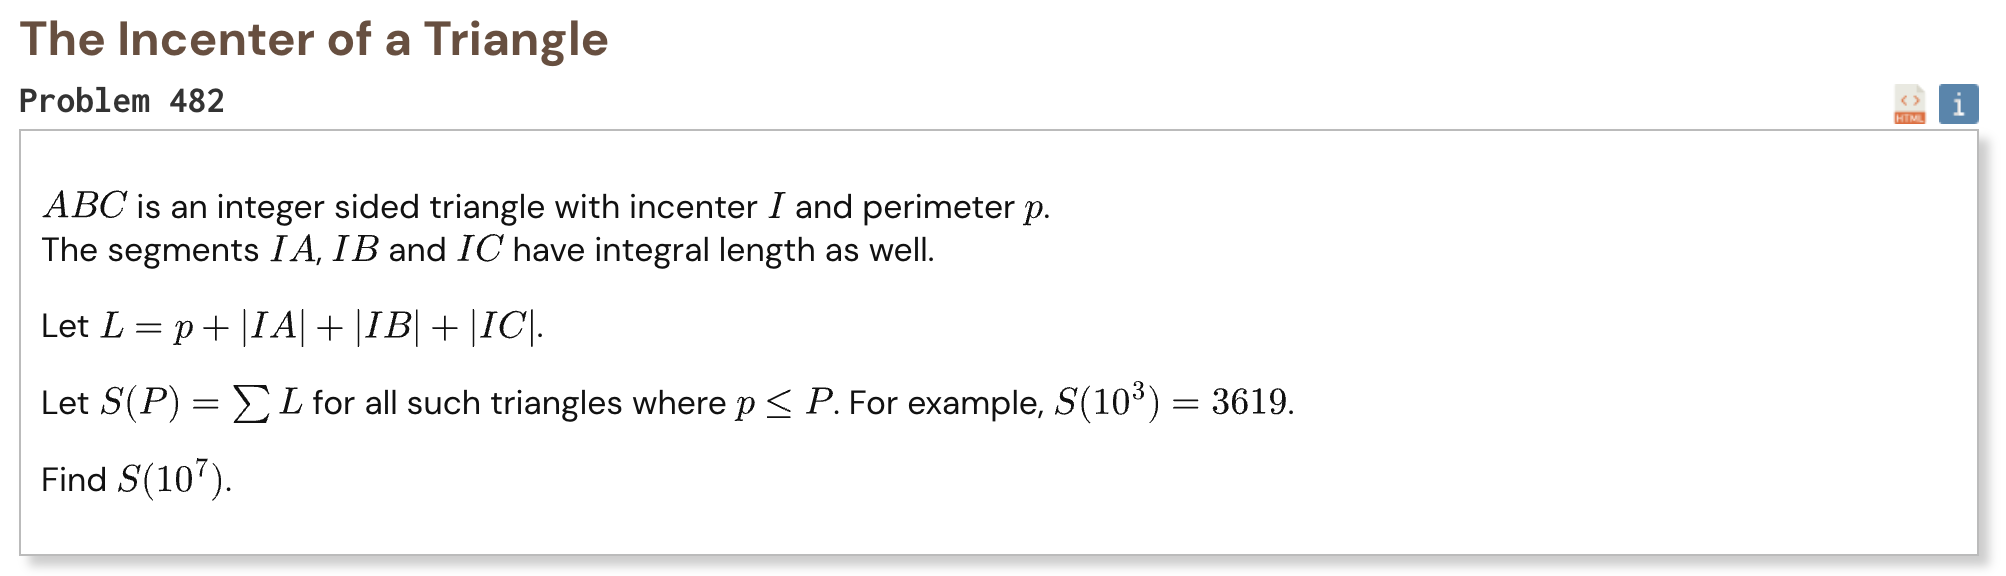

## Initial approach

- rewrite the triangle using the three tangent lengths around the incircle
- integer distances from the incenter create three Pythagorean triples sharing the same inradius
- for each possible inradius, generate all valid tangent lengths from divisors of its square
- choose two tangent lengths and calculate the third one directly
- keep only integer solutions that also satisfy the perimeter limit
- sort the three lengths to avoid counting the same triangle more than once
- add the perimeter and the three incenter distances for every valid triangle

In [1]:
%%time

from math import isqrt

P = 10**7
RMAX = isqrt(P * P // 108)

spf = list(range(RMAX + 1))

for p in range(2, isqrt(RMAX) + 1):
    if spf[p] == p:
        for x in range(p * p, RMAX + 1, p):
            if spf[x] == x:
                spf[x] = p

def factorize(n):
    factors = []

    while n > 1:
        p = spf[n]
        exponent = 0

        while n % p == 0:
            n //= p
            exponent += 1

        factors.append((p, exponent))

    return factors

def divisors_of_square(factors):
    divisors = [1]

    for p, exponent in factors:
        new_divisors = []
        power = 1

        for _ in range(2 * exponent + 1):
            for d in divisors:
                new_divisors.append(d * power)

            power *= p

        divisors = new_divisors

    return divisors

result = 0

for r in range(1, RMAX + 1):
    r2 = r * r
    factors = factorize(r)
    divisors = divisors_of_square(factors)

    candidates = {}

    for d in divisors:
        if d >= r:
            continue

        e = r2 // d

        if (d + e) % 2 != 0:
            continue

        x = (e - d) // 2
        distance = (e + d) // 2

        if 2 * x < P:
            candidates[x] = distance

    xs = sorted(candidates)

    for i, x in enumerate(xs):
        for y in xs[i:]:
            if 2 * (x + y + y) > P:
                break

            denominator = x * y - r2

            if denominator <= 0:
                continue

            numerator = r2 * (x + y)

            if numerator % denominator != 0:
                continue

            z = numerator // denominator

            if z < y:
                continue

            if 2 * (x + y + z) > P:
                continue

            if z not in candidates:
                continue

            perimeter = 2 * (x + y + z)

            result += (
                perimeter
                + candidates[x]
                + candidates[y]
                + candidates[z]
            )

print("Result:", result)

Result: 1400824879147
CPU times: user 38.9 s, sys: 156 ms, total: 39.1 s
Wall time: 39.2 s
